<!-- LAB_START -->
# 금융AI: Diffusion Models
## Week 2 — Probability Foundations for Diffusion Models
### Integrated Lab + Assignment

이 문서는 확률분포 → Gaussian sampling → Monte Carlo → reparameterization → multivariate dependence → forward diffusion → 금융 위험측도의 연결을 실험으로 확인합니다.

학습목표는 random variable과 realization 구별, Gaussian moments 검증, Monte Carlo와 오차 이해, affine reparameterization, 상관 시나리오 생성, forward diffusion의 Gaussian 해석, 생성 표본 기반 위험측정입니다. 모든 금융 예시는 합성 데이터이며 실제 수익률이 Gaussian이라는 주장이 아닙니다.

## Reproducible setup

모든 실험은 고정 seed와 함수별 독립 난수 stream을 사용합니다. 표와 그림은 instructor outputs에 저장되며 notebook에도 결과가 embedded됩니다.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

# 원래 노트북은 상위 폴더의 Diffusion_week02_lab_assignment.py 모듈을 불러옵니다.
# 그 파일이 있으면 그대로 사용하고, 없으면 아래의 대체 구현을 사용합니다.
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
try:
    from Diffusion_week02_lab_assignment import *  # 교수님 원본 모듈
    print("원본 모듈(Diffusion_week02_lab_assignment.py)을 불러왔습니다.")
except ModuleNotFoundError:
    print("원본 모듈이 없어 노트북 내장 대체 코드를 사용합니다.")

    import numpy as np
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt
    from statistics import NormalDist

    SEED = 2026
    FIGURE_DIR = Path.cwd() / "outputs" / "figures"
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    _N01 = NormalDist()

    def _rng(stream: int) -> np.random.Generator:
        """함수마다 독립적인 난수 stream (재현 가능)."""
        return np.random.default_rng([SEED, stream])

    def _npdf(x, mu=0.0, sigma=1.0):
        x = np.asarray(x, dtype=float)
        return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

    def _save(fig, name):
        fig.tight_layout()
        fig.savefig(FIGURE_DIR / name, dpi=150, bbox_inches="tight")
        plt.close(fig)

    # ---------------- Lab 1 ----------------
    def lab_1_standard_gaussian(n: int = 100_000) -> pd.DataFrame:
        eps = _rng(1).standard_normal(n)
        table = pd.DataFrame({
            "Quantity": ["E[eps]", "Var(eps)", "P(eps <= 0)", "P(|eps| <= 1.96)"],
            "Theoretical": [0.0, 1.0, 0.5, 2 * _N01.cdf(1.96) - 1],
            "Empirical": [eps.mean(), eps.var(ddof=1), np.mean(eps <= 0),
                          np.mean(np.abs(eps) <= 1.96)],
        })
        table["AbsDiff"] = (table["Empirical"] - table["Theoretical"]).abs()

        fig, ax = plt.subplots(figsize=(9, 4.5))
        ax.hist(eps, bins=120, density=True, alpha=0.45, color="tab:blue",
                label=f"Samples (N={n:,})")
        grid = np.linspace(-4.5, 4.5, 500)
        ax.plot(grid, _npdf(grid), color="black", lw=2, label="N(0,1) PDF")
        ax.axvspan(-1.96, 1.96, color="tab:orange", alpha=0.08, label="|eps| <= 1.96")
        ax.set(title="Standard Gaussian sampling", xlabel="eps", ylabel="Density")
        ax.legend()
        _save(fig, "01_standard_gaussian.png")
        return table.round(5)

    # ---------------- Lab 2 ----------------
    def lab_2_reparameterization(mu: float = 0.001, sigma: float = 0.02,
                                 n: int = 100_000) -> pd.DataFrame:
        eps = _rng(2).standard_normal(n)
        r = mu + sigma * eps
        table = pd.DataFrame({
            "Quantity": ["E[R] = mu", "Var(R) = sigma^2", "Std(R) = sigma"],
            "Theoretical": [mu, sigma ** 2, sigma],
            "Empirical": [r.mean(), r.var(ddof=1), r.std(ddof=1)],
        })
        table["AbsDiff"] = (table["Empirical"] - table["Theoretical"]).abs()

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        grid = np.linspace(-4.5, 4.5, 500)
        axes[0].hist(eps, bins=120, density=True, alpha=0.45, color="tab:gray")
        axes[0].plot(grid, _npdf(grid), color="black", lw=2)
        axes[0].set(title="Noise eps ~ N(0,1)", xlabel="eps", ylabel="Density")
        g2 = mu + sigma * grid
        axes[1].hist(r, bins=120, density=True, alpha=0.45, color="tab:blue",
                     label="Generated R")
        axes[1].plot(g2, _npdf(g2, mu, sigma), color="black", lw=2,
                     label="N(mu, sigma^2) PDF")
        axes[1].axvline(mu, color="tab:red", ls="--", label=f"mu = {mu}")
        axes[1].set(title=f"R = {mu} + {sigma} * eps (synthetic)",
                    xlabel="Return", ylabel="Density")
        axes[1].legend()
        _save(fig, "02_reparameterization_returns.png")
        return table.round(7)

    # ---------------- Lab 3 ----------------
    def lab_3_monte_carlo(sizes=(10, 100, 1_000, 10_000, 100_000, 1_000_000)) -> pd.DataFrame:
        rng = _rng(3)
        rows = []
        for n in sizes:
            eps = rng.standard_normal(n)
            est = np.mean(eps ** 2)
            rows.append({"N": n, "Estimate": est, "TrueValue": 1.0,
                         "AbsError": abs(est - 1.0)})
        table = pd.DataFrame(rows)

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        axes[0].plot(table["N"], table["Estimate"], "o-", color="tab:blue",
                     label="MC estimate of E[eps^2]")
        axes[0].axhline(1.0, color="black", ls="--", label="True value = 1")
        axes[0].set(xscale="log", title="Monte Carlo estimate", xlabel="N",
                    ylabel="Estimate")
        axes[0].legend()
        axes[1].plot(table["N"], table["AbsError"], "o-", color="tab:red")
        axes[1].set(xscale="log", yscale="log", title="Absolute error |m_N - 1|",
                    xlabel="N", ylabel="AbsError")
        _save(fig, "03_monte_carlo_error.png")
        return table.round(6)

    # ---------------- Lab 4 ----------------
    def lab_4_correlation_comparison(rhos=(0.10, 0.65, 0.90), sigma1: float = 0.015,
                                     sigma2: float = 0.025, n: int = 5_000) -> pd.DataFrame:
        mu = np.array([0.0005, 0.0008])
        rows = []
        fig, axes = plt.subplots(1, len(rhos), figsize=(5 * len(rhos), 4.6),
                                 sharex=True, sharey=True)
        for k, (rho, ax) in enumerate(zip(rhos, axes)):
            cov = np.array([[sigma1 ** 2, rho * sigma1 * sigma2],
                            [rho * sigma1 * sigma2, sigma2 ** 2]])
            L = np.linalg.cholesky(cov)
            eps = _rng(40 + k).standard_normal((n, 2))
            X = mu + eps @ L.T
            r1, r2 = X[:, 0], X[:, 1]
            emp_rho = np.corrcoef(r1, r2)[0, 1]
            emp_beta = np.cov(r1, r2, ddof=1)[0, 1] / np.var(r1, ddof=1)
            rows.append({"rho_target": rho, "rho_empirical": emp_rho,
                         "sigma1_empirical": r1.std(ddof=1),
                         "sigma2_empirical": r2.std(ddof=1),
                         "beta_2|1_theory": rho * sigma2 / sigma1,
                         "beta_2|1_empirical": emp_beta})
            ax.scatter(r1, r2, s=4, alpha=0.3)
            xs = np.linspace(r1.min(), r1.max(), 50)
            ax.plot(xs, mu[1] + emp_beta * (xs - mu[0]), color="tab:red", lw=2,
                    label=f"OLS slope = {emp_beta:.2f}")
            ax.set(title=f"rho = {rho:.2f} (empirical {emp_rho:.3f})",
                   xlabel="R1", ylabel="R2")
            ax.legend(loc="upper left")
        fig.suptitle("Correlated scenarios via Cholesky: sigma1=1.5%, sigma2=2.5%")
        _save(fig, "04_correlation_comparison.png")
        return pd.DataFrame(rows).round(4)

    # ---------------- Lab 5 ----------------
    def lab_5_forward_diffusion(S: int = 1000, steps=(0, 50, 100, 250, 500, 999),
                                length: int = 64) -> pd.DataFrame:
        betas = np.linspace(1e-4, 0.02, S)
        alpha_bar = np.cumprod(1.0 - betas)
        t = np.arange(length)
        x0 = 0.8 * np.sin(2 * np.pi * t / 32) + 0.4 * np.sign(np.sin(2 * np.pi * t / 64))
        rng = _rng(5)
        rows, paths = [], {}
        for s in steps:
            ab = alpha_bar[s]
            eps = rng.standard_normal(length)
            xs = np.sqrt(ab) * x0 + np.sqrt(1 - ab) * eps
            paths[s] = xs
            rows.append({"s": s, "alpha_bar_s": ab, "signal_coef sqrt(ab)": np.sqrt(ab),
                         "noise_coef sqrt(1-ab)": np.sqrt(1 - ab),
                         "corr(x_s, x_0)": np.corrcoef(xs, x0)[0, 1]})

        fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True, sharey=True)
        for ax, s in zip(axes.ravel(), steps):
            ax.plot(t, x0, color="black", lw=1, alpha=0.5, label="x_0")
            ax.plot(t, paths[s], color="tab:blue", lw=1.3, label="x_s")
            ax.set_title(f"s = {s}, alpha_bar = {alpha_bar[s]:.3f}")
        axes[0, 0].legend()
        fig.suptitle("Forward diffusion: x_s = sqrt(alpha_bar) x_0 + sqrt(1-alpha_bar) eps "
                     "(synthetic pattern)")
        _save(fig, "05_forward_diffusion_paths.png")
        return pd.DataFrame(rows).round(4)

    # ---------------- Risk measures ----------------
    def _gauss_lpm(mu, sigma, target):
        d = (target - mu) / sigma
        Phi, phi = _N01.cdf(d), _N01.pdf(d)
        lpm0 = Phi
        lpm1 = sigma * (d * Phi + phi)
        lpm2 = sigma ** 2 * ((d ** 2 + 1) * Phi + d * phi)
        return lpm0, lpm1, lpm2

    def risk_exposition(mu: float = 0.001) -> pd.DataFrame:
        rows = []
        for sigma in (0.01, 0.03):
            for target in (0.0, 0.01, 0.03):
                lpm0, lpm1, lpm2 = _gauss_lpm(mu, sigma, target)
                dd = np.sqrt(lpm2)
                rows.append({"mu": mu, "sigma": sigma, "target r*": target,
                             "P(R<r*) = LPM0": lpm0, "LPM1 (mean shortfall)": lpm1,
                             "DownsideDev": dd, "Sortino": (mu - target) / dd})
        table = pd.DataFrame(rows)

        # 06: 같은 mean, 다른 volatility
        fig, ax = plt.subplots(figsize=(10, 4.8))
        grid = np.linspace(-0.11, 0.11, 800)
        for sigma, color in ((0.01, "tab:blue"), (0.03, "tab:orange")):
            pdf = _npdf(grid, mu, sigma)
            p = _N01.cdf((0 - mu) / sigma)
            ax.plot(grid, pdf, color=color, lw=2, label=f"sigma = {sigma:.0%}")
            ax.fill_between(grid, pdf, where=grid < 0, color=color, alpha=0.2,
                            label=f"P(R<0) = {p:.3f} (sigma={sigma:.0%})")
        ax.axvline(0, color="black", ls="--", label="Target r* = 0")
        ax.set(title=f"Shortfall risk: same mean ({mu:.1%}), different volatility",
               xlabel="Return", ylabel="Density")
        ax.legend(fontsize=9)
        _save(fig, "06_shortfall_risk_comparison.png")

        # 07: 같은 분포, 다른 target
        sigma = 0.02
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
        grid = np.linspace(-0.08, 0.08, 800)
        pdf = _npdf(grid, mu, sigma)
        for ax, target in zip(axes, (0.0, 0.01, 0.03)):
            p = _N01.cdf((target - mu) / sigma)
            ax.plot(grid, pdf, color="black", lw=2)
            ax.fill_between(grid, pdf, where=grid < target, color="tab:blue", alpha=0.25)
            ax.axvline(target, color="tab:blue", ls="--")
            ax.set(title=f"r* = {target:.0%}:  P(R<r*) = {p:.3f}", xlabel="Return")
        axes[0].set_ylabel("Density")
        fig.suptitle(f"Shortfall probability rises with the target (mu={mu:.1%}, sigma={sigma:.0%})")
        _save(fig, "07_shortfall_risk_targets.png")

        # 08: Shortfall region, VaR, ES (mu=0.05%, sigma=2%)
        mu8, s8, alpha = 0.0005, 0.02, 0.05
        z = _N01.inv_cdf(alpha)
        q = mu8 + s8 * z
        es = mu8 - s8 * _N01.pdf(z) / alpha
        grid = np.linspace(-0.09, 0.09, 900)
        pdf = _npdf(grid, mu8, s8)
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(grid, pdf, color="black", lw=2.2, label="Return density")
        ax.fill_between(grid, pdf, where=grid < 0, color="tab:blue", alpha=0.12,
                        label="Shortfall region $R<r^*$")
        ax.fill_between(grid, pdf, where=grid <= q, color="tab:red", alpha=0.35,
                        label="Worst 5% tail")
        ax.axvline(0, color="tab:blue", ls="--", label="Target $r^*=0$")
        ax.axvline(q, color="tab:red", ls="--", label=f"5% return quantile = {q:.2%}")
        ax.axvline(es, color="purple", ls=":", lw=3, label=f"Expected Shortfall = {es:.2%}")
        ax.set(title="Shortfall region, Value at Risk boundary, and Expected Shortfall",
               xlabel="Return", ylabel="Density")
        ax.legend(fontsize=9)
        _save(fig, "08_shortfall_var_es_comparison.png")
        return table.round(5)

print(f"SEED={SEED}")
print(f"FIGURE_DIR={FIGURE_DIR}")

원본 모듈이 없어 노트북 내장 대체 코드를 사용합니다.
SEED=2026
FIGURE_DIR=c:\Users\User\OneDrive\문서\중앙대학교\금융인공지능\outputs\figures


# 1. From Probability Distribution to Samples

$X\sim p_X(x)$에서 $X$는 random variable, $p_X$는 distribution, sampling으로 나온 $x^{(i)}$는 realization입니다. 분포는 한 관측값이 아니라 가능한 값 전체의 확률 구조입니다.

금융에서는 $R_{t+1}\sim p(r\mid X_t)$가 단일 point forecast $\hat R_{t+1}$보다 상승·하락 가능성과 tail uncertainty를 더 풍부하게 표현합니다. 생성형 AI의 목적은 한 숫자가 아니라 조건부 분포를 학습하고 sampling하는 것입니다.

## Lab 1 — Standard Gaussian Sampling

$$\epsilon\sim\mathcal N(0,1),\quad E[\epsilon]=0,\quad \operatorname{Var}(\epsilon)=1.$$

$\epsilon$은 standard Gaussian random variable입니다. 대칭성으로 $P(\epsilon\le0)=0.5$, 중앙 95% 규칙으로 $P(|\epsilon|\le1.96)\approx0.95$. 유한 sample의 통계량은 random이므로 이론값과 정확히 같지 않지만 큰 표본에서는 가까워집니다. Gaussian noise는 diffusion의 기본 randomness이므로 먼저 그 성질을 검증합니다.

,Quantity,Theoretical,Empirical,AbsDiff
0,E[eps],0.00,0.00009,0.00009
1,Var(eps),1.00,0.99408,0.00592
2,P(eps <= 0),0.50,0.49840,0.00160
3,P(|eps| <= 1.96),0.95,0.95171,0.00171


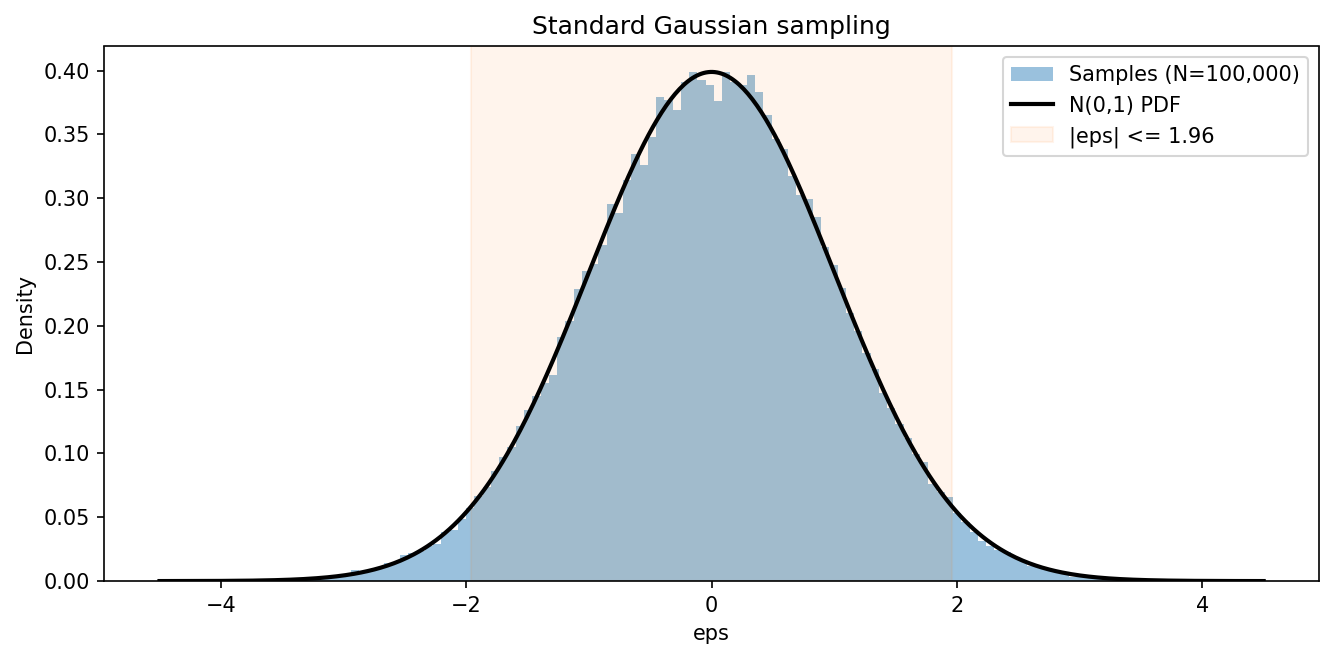

In [2]:
lab1 = lab_1_standard_gaussian(); display(lab1)
display(Image(filename=str(FIGURE_DIR / "01_standard_gaussian.png")))

**Interpretation.** Histogram은 theoretical PDF를 따르고 moments와 확률은 목표에 가깝습니다. 차이는 sampling variability입니다. 다음 Lab에서는 같은 noise를 이동·확대합니다.

# 2. Gaussian Reparameterization

$$\epsilon\sim\mathcal N(0,1),\qquad X=\mu+\sigma\epsilon.$$
$$E[X]=\mu+\sigma E[\epsilon]=\mu,$$
$$\operatorname{Var}(X)=\sigma^2\operatorname{Var}(\epsilon)=\sigma^2.$$

$\epsilon$은 randomness, $\mu$는 location, $\sigma$는 scale, $X$는 generated variable입니다. 즉 randomness와 distribution parameters가 분리됩니다. 이 separation은 neural network가 distribution-related quantity를 학습하고 별도 noise로 sample을 만들게 하는 핵심입니다.

## Lab 2 — Illustrative Financial Return

$R=0.001+0.02\epsilon$을 생성하여 $\hat\mu\approx\mu$와 $\widehat{\operatorname{Var}}(R)\approx\sigma^2$를 확인합니다. 실제 금융수익률은 heavy tails, skewness, volatility clustering, regime changes를 가질 수 있습니다. Gaussian은 여기서 수학적 building block일 뿐입니다.

,Quantity,Theoretical,Empirical,AbsDiff
0,E[R] = mu,0.0010,0.001097,0.000097
1,Var(R) = sigma^2,0.0004,0.000399,0.000001
2,Std(R) = sigma,0.0200,0.019976,0.000024


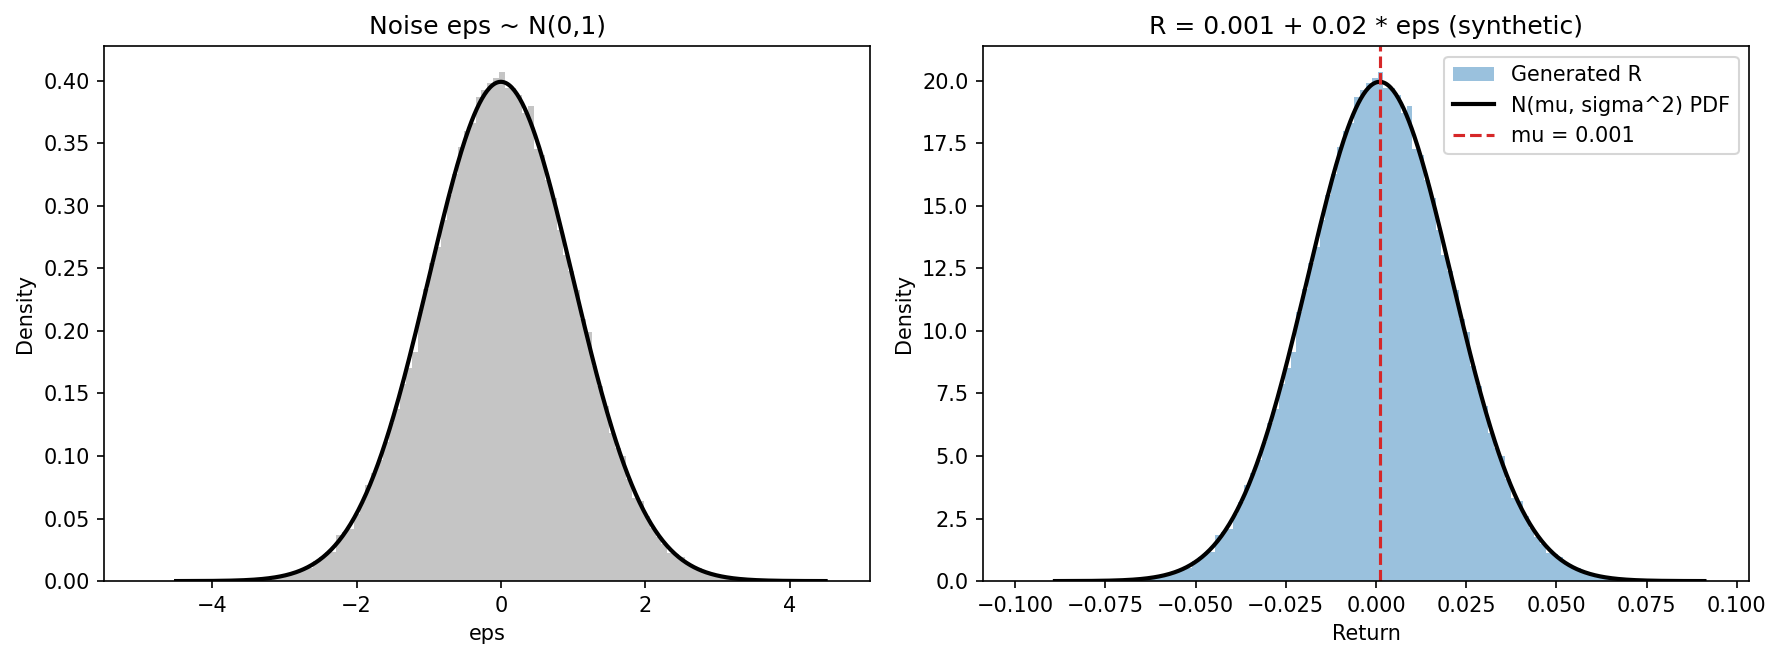

In [3]:
lab2 = lab_2_reparameterization(); display(lab2)
display(Image(filename=str(FIGURE_DIR / "02_reparameterization_returns.png")))

**Interpretation.** $\mu$는 중심, $\sigma$는 퍼짐을 통제하며 $\epsilon$이 realization마다 변합니다. 이제 sample average로 expectation을 계산합니다.

# 3. Lab 3 — Monte Carlo and the Law of Large Numbers

## What random variables are we generating?

$$\epsilon_i\overset{iid}{\sim}\mathcal N(0,1),\qquad i=1,\ldots,N.$$

`iid`는 **independent and identically distributed**: 서로 독립이며 모두 같은 standard Gaussian distribution을 따른다는 뜻입니다.

## Exactly what quantity is estimated?

$$E[\epsilon]=0,\qquad \operatorname{Var}(\epsilon)=1.$$
$$\operatorname{Var}(\epsilon)=E[\epsilon^2]-(E[\epsilon])^2$$
이므로 $1=E[\epsilon^2]-0$, 따라서
$$\boxed{E[\epsilon^2]=1}.$$

이것이 코드 실행 전에 알아야 할 theoretical target입니다.

## Monte Carlo estimator, symbols, and integral

$$m=E[\epsilon^2]=1,\qquad \boxed{\hat m_N=\frac1N\sum_{i=1}^N\epsilon_i^2}.$$

이는
$$E[\epsilon^2]=\int_{-\infty}^{\infty}\epsilon^2\phi(\epsilon)\,d\epsilon$$
의 numerical approximation입니다. $\phi$는 standard normal PDF, $N$은 Monte Carlo sample size, $\epsilon_i$는 generated draw, $\hat m_N$은 estimate, $m=1$은 known true value입니다.

오차를
$$\boxed{\mathrm{Error}_N=|\hat m_N-m|=|\hat m_N-1|}$$
로 정의합니다. 따라서 표의 `AbsError`는 estimate와 $E[\epsilon^2]=1$ 사이의 absolute distance입니다.

## Numerical toy example before code

$\epsilon=(0.3,-1.1,0.7,0.2,-0.6)$이면
$$\hat m_5=\frac{0.3^2+(-1.1)^2+0.7^2+0.2^2+(-0.6)^2}{5}=0.438.$$
따라서 $\mathrm{Error}_5=|0.438-1|=0.562$. 표본이 5개뿐이므로 정확히 1일 이유가 없습니다.

Law of Large Numbers는
$$\hat m_N\xrightarrow{p}E[\epsilon^2]=1$$
을 말합니다. $\xrightarrow{p}$는 **convergence in probability**입니다. 중요한 점은 realized absolute error가 매번 단조 감소할 필요가 없다는 것입니다. 한 실행에서 $|\hat m_{100}-1|<|\hat m_{1000}-1|$도 가능합니다. LLN은 큰 $N$에서의 probabilistic convergence이지 매 경로의 monotone decline이 아닙니다.

,N,Estimate,TrueValue,AbsError
0,10,0.772033,1.0,0.227967
1,100,0.827858,1.0,0.172142
2,1000,0.983120,1.0,0.016880
3,10000,1.002619,1.0,0.002619
4,100000,1.000350,1.0,0.000350
5,1000000,1.000003,1.0,0.000003


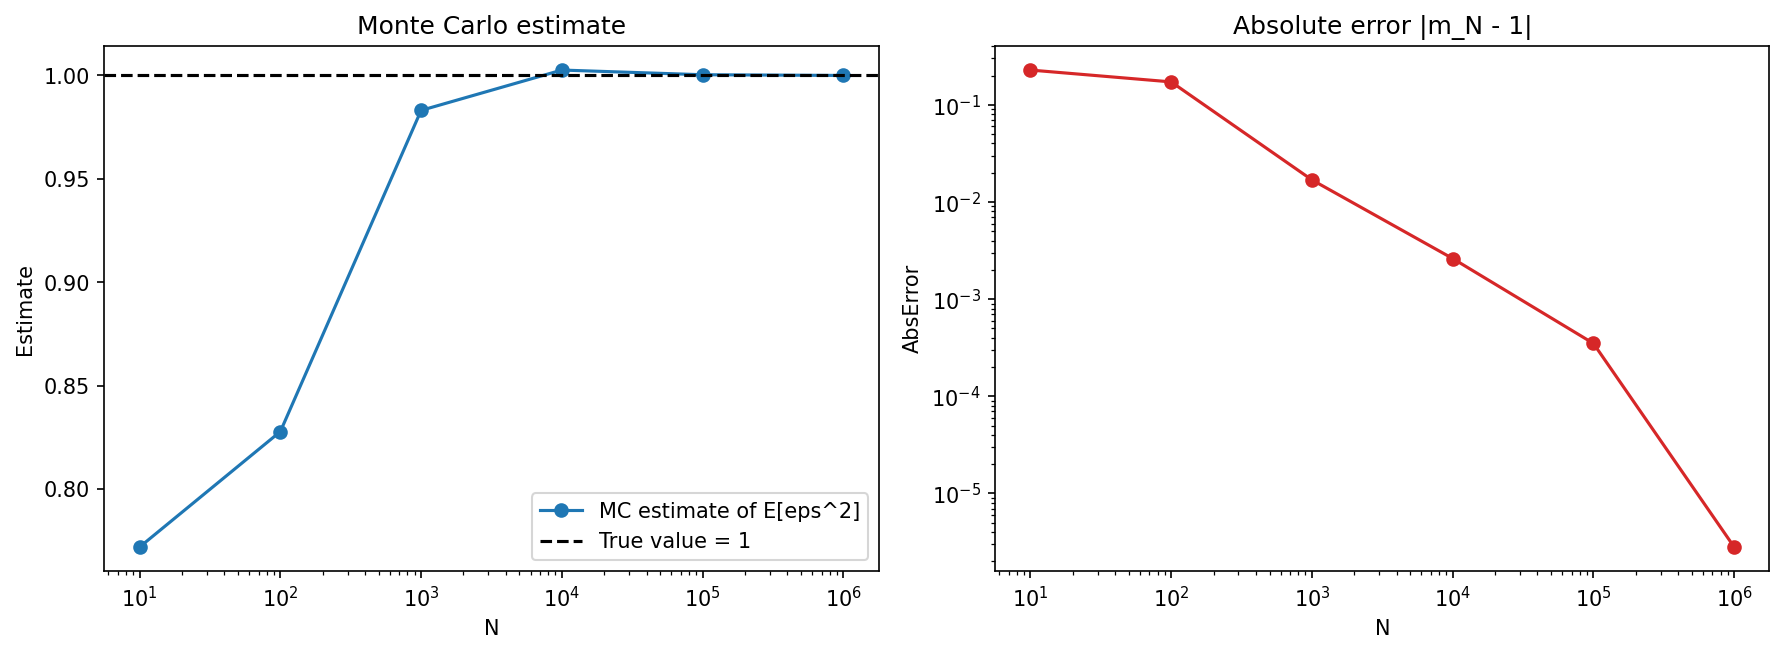

In [4]:
lab3 = lab_3_monte_carlo(); display(lab3)
display(Image(filename=str(FIGURE_DIR / "03_monte_carlo_error.png")))

**Interpretation.** 큰 $N$에서는 estimate가 대체로 1 근처에 안정되지만 인접 행의 `AbsError`는 오르기도 합니다. Assignment 1은 반복실험으로 typical error scale을 측정합니다.

# Monte Carlo Simulation vs Diffusion Models

$$\boxed{\text{Monte Carlo Simulation}\neq\text{Diffusion Model}}$$

둘 다 random sampling을 사용하지만 해결하는 문제는 다릅니다.

## Monte Carlo
이미 지정된 model $R\sim\mathcal N(\mu,\sigma^2)$에서
$$R^{(m)}=\mu+\sigma\epsilon^{(m)},\quad m=1,\ldots,M$$
을 생성한 뒤
$$E[R]\approx M^{-1}\sum_mR^{(m)},\qquad P(R<0)\approx M^{-1}\sum_m\mathbf1\{R^{(m)}<0\}$$
처럼 적분·확률을 근사합니다.

**Known/assumed distribution → random sampling → numerical approximation.** Monte Carlo는 주로 numerical integration/probabilistic estimation method입니다.

## Diffusion

Diffusion은 unknown complex $p_{\mathrm{data}}(x)$, 금융에서는
$$p_{\mathrm{data}}(R_{t+1:t+H}\mid X_t)$$
를 다룹니다. 이는 heavy tails, volatility clustering, nonlinear dependence, nonstationarity, regime shifts, asymmetry를 포함할 수 있습니다. Forward process는 $x_0\to x_1\to\cdots\to x_S$로 data를 인공 손상하고, model은 $x_S\to\cdots\to x_0$의 reverse dynamics를 학습합니다.

**Unknown complex distribution → learn reverse generative dynamics → generate new samples.** Diffusion은 단순 simulation routine이 아니라 learned generative model입니다.

## Concrete 20-day financial example and the connection

미래경로는 $R_{t+1:t+20}=(R_{t+1},\ldots,R_{t+20})$입니다. Traditional Monte Carlo에서는 연구자가 먼저 $R_{t+h}=\mu+\sigma\epsilon_{t+h}$ 같은 model을 지정합니다. Diffusion에서는 전체 경로에 단순 Gaussian을 강제하지 않고 $p_\theta(R_{t+1:t+20}\mid X_t)$를 학습합니다. 둘 다 최종적으로 $R^{(1)},\ldots,R^{(M)}$을 만들 수 있지만 출발점이 다릅니다.

$$\boxed{\text{Diffusion generates scenarios}\rightarrow\text{Monte Carlo summarizes scenarios}}$$

> **Diffusion = distribution learning + scenario generation**  
> **Monte Carlo = sample-based numerical estimation**

# 4. Multivariate Gaussian and Correlation

$\mathbf X=\boldsymbol\mu+L\boldsymbol\epsilon$, $\boldsymbol\epsilon\sim\mathcal N(\mathbf0,I)$, $LL^\top=\Sigma$이면 $E[\mathbf X]=\boldsymbol\mu$, $\operatorname{Cov}(\mathbf X)=\Sigma$. Cholesky factor $L$이 independent noise를 correlated joint scenarios로 바꿉니다.

$$\rho=\frac{\operatorname{Cov}(R_1,R_2)}{\sigma_1\sigma_2},\qquad \beta_{2|1}=\rho\frac{\sigma_2}{\sigma_1}.$$

$\rho$는 linear association의 strength와 direction이고 scatter cloud의 geometric slope 자체가 아닙니다. $\sigma_1=1.5\%$, $\sigma_2=2.5\%$를 고정하고 $\rho=0.10$, $\rho=0.65$, $\rho=0.90$을 비교합니다.

,rho_target,rho_empirical,sigma1_empirical,sigma2_empirical,beta_2|1_theory,beta_2|1_empirical
0,0.10,0.1239,0.0149,0.0249,0.1667,0.2073
1,0.65,0.6558,0.0155,0.0253,1.0833,1.0700
2,0.90,0.8965,0.0150,0.0246,1.5000,1.4693


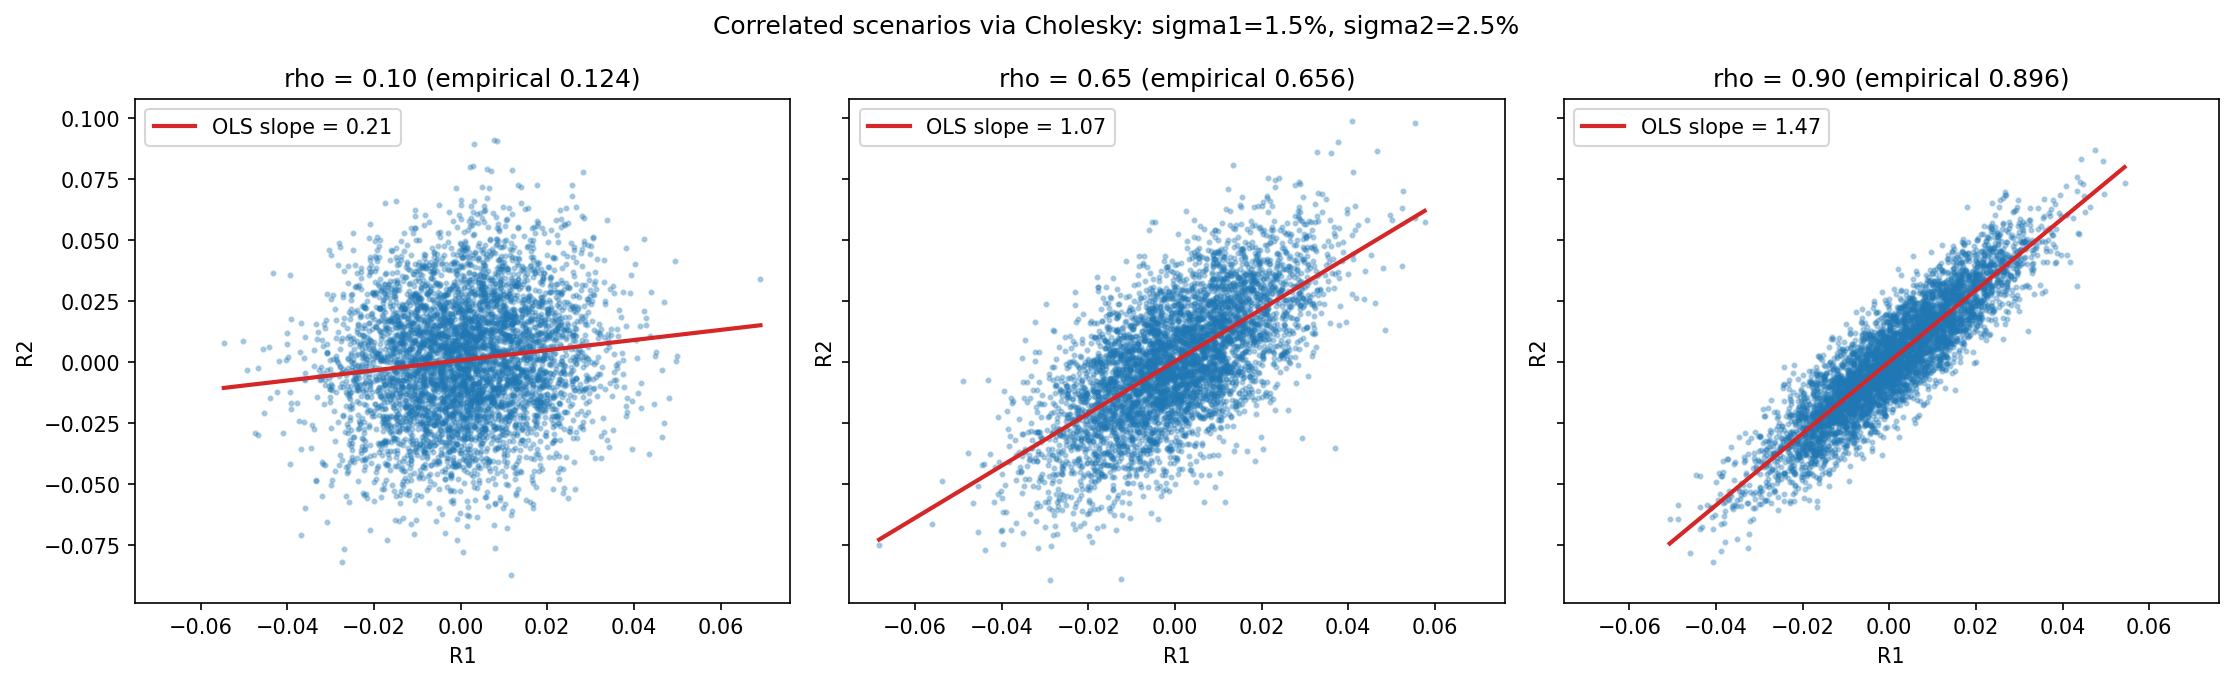

In [4]:
lab4 = lab_4_correlation_comparison(); display(lab4)
display(Image(filename=str(FIGURE_DIR / "04_correlation_comparison.png")))

**Interpretation.** $\rho$가 커질수록 cloud가 더 좁고 선형적으로 정렬됩니다. 그러나 regression slope에는 volatility ratio도 곱해지므로 correlation과 slope를 동일시하면 안 됩니다.

# 5. Forward Diffusion as Reparameterization

$$x_s=\sqrt{\bar\alpha_s}x_0+\sqrt{1-\bar\alpha_s}\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$
$\mu_s=\sqrt{\bar\alpha_s}x_0$, $\sigma_s=\sqrt{1-\bar\alpha_s}$로 두면 $x_s=\mu_s+\sigma_s\epsilon$이고
$$q(x_s\mid x_0)=\mathcal N(\sqrt{\bar\alpha_s}x_0,(1-\bar\alpha_s)I).$$

$x_0$는 original data, $s$는 diffusion step, $\alpha_s$는 stepwise signal retention, $\bar\alpha_s$는 cumulative retention, $x_s$는 noisy observation입니다. **$s$는 diffusion time이지 financial calendar time $t$가 아닙니다. Forward diffusion은 forecasting이 아닙니다.** 이는 structured, step-dependent Gaussian reparameterization입니다.

,s,alpha_bar_s,signal_coef sqrt(ab),noise_coef sqrt(1-ab),"corr(x_s, x_0)"
0,0,0.9999,0.9999,0.0100,0.9999
1,50,0.9700,0.9849,0.1733,0.9823
2,100,0.8951,0.9461,0.3238,0.9105
3,250,0.5214,0.7221,0.6918,0.5215
4,500,0.0778,0.2789,0.9603,0.2183
5,999,0.0000,0.0064,1.0000,-0.0037


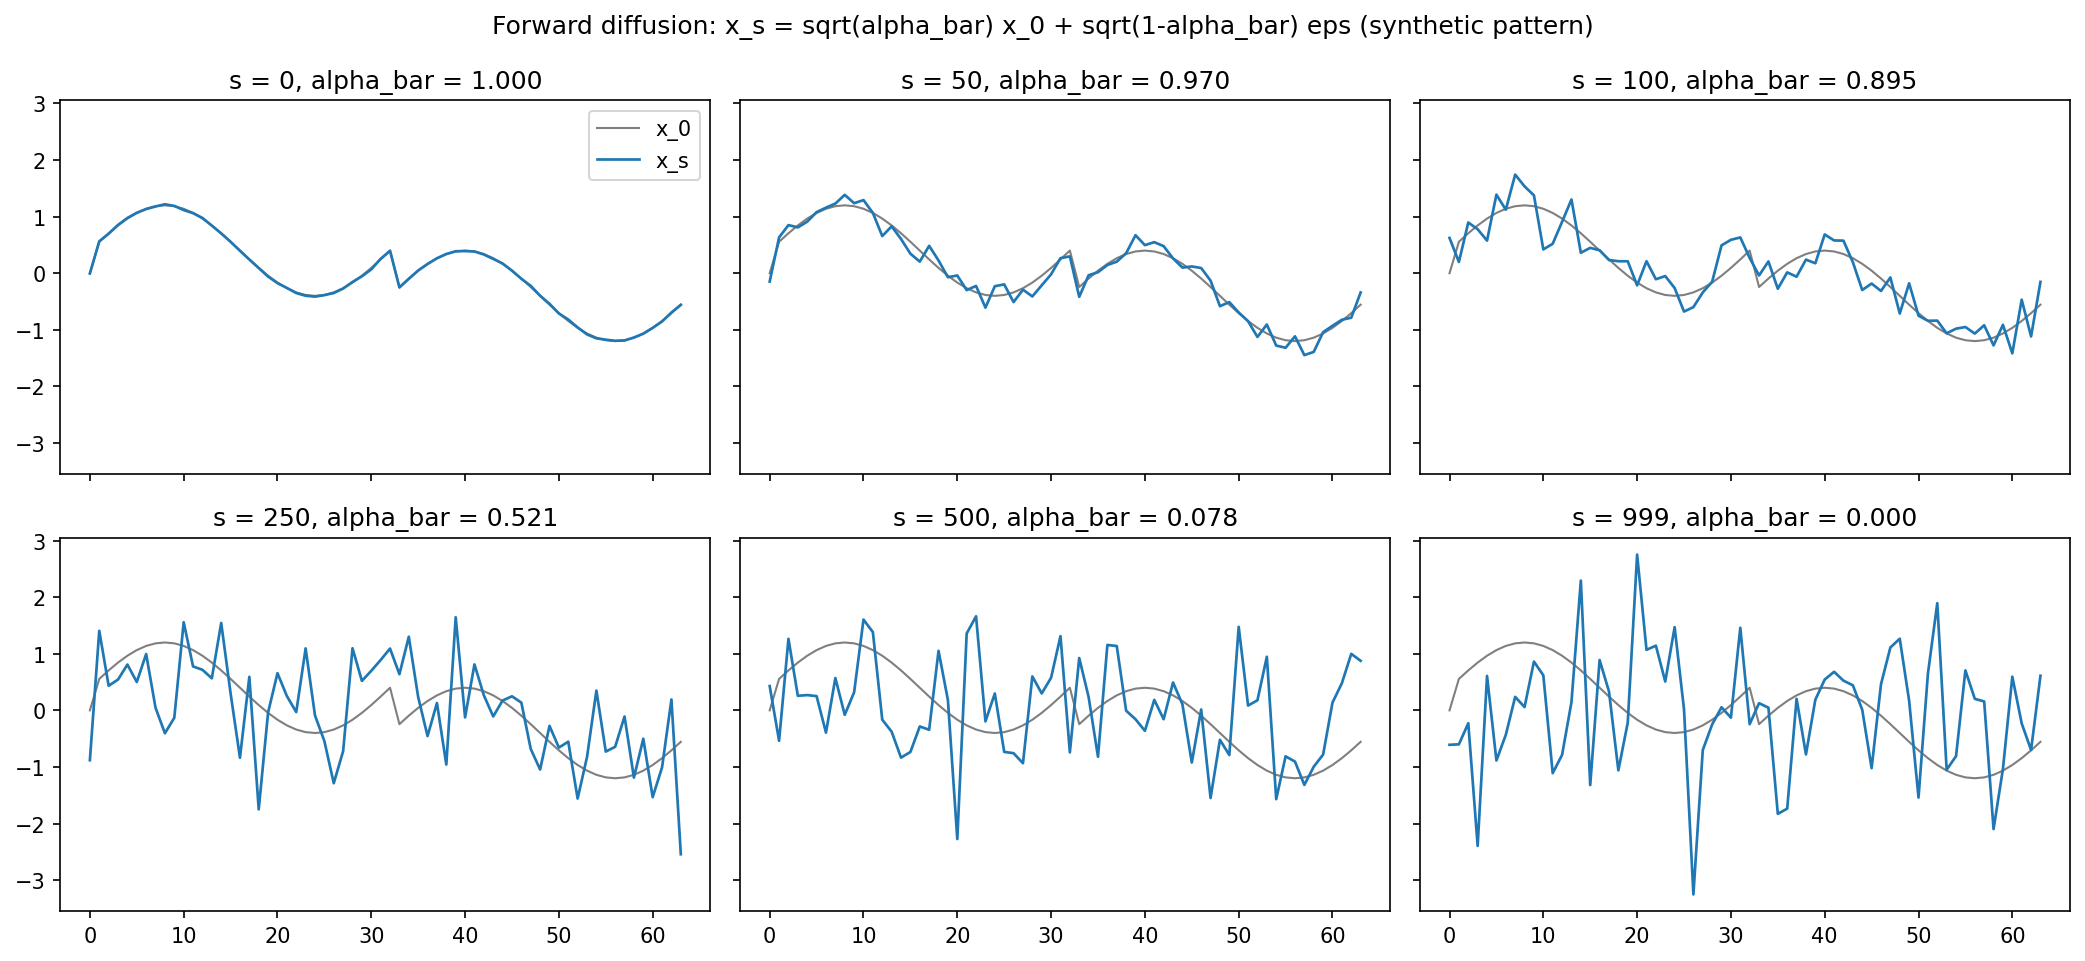

In [6]:
lab5 = lab_5_forward_diffusion(); display(lab5)
display(Image(filename=str(FIGURE_DIR / "05_forward_diffusion_paths.png")))

**Interpretation.** $\bar\alpha_s$가 작아지면 signal coefficient는 줄고 noise coefficient는 커져 synthetic original pattern이 사라집니다. 이는 학습용 artificial corruption입니다.

# From Generated Scenarios to Financial Risk Measures

## Shortfall Risk

target return $r^*$에 대해 shortfall event는 $R<r^*$이고
$$\boxed{P(R<r^*)}$$
는 realized return이 required target에 미달할 확률입니다. $r^*=0$이면 negative-return probability, $r^*=0.03$이면 3% 수익을 달성하지 못할 확률입니다.

shortfall amount는
$$\boxed{(r^*-R)^+=\max(r^*-R,0)}.$$
$r^*=0,R=-0.03$이면 0.03, $R=0.05$이면 0입니다.

## Lower Partial Moments, downside risk, and Sortino

$$\boxed{LPM_n(r^*)=E[\max(r^*-R,0)^n]}.$$

- $n=0$: $LPM_0=P(R<r^*)$, shortfall probability
- $n=1$: $LPM_1=E[(r^*-R)^+]$, **expected target shortfall / mean shortfall amount**
- $n=2$: 큰 downside deviation을 더 강하게 벌점

$$\mathrm{DownsideDeviation}=\sqrt{E[((r^*-R)^+)^2]},\qquad
\mathrm{Sortino}=\frac{E[R]-r^*}{\mathrm{DownsideDeviation}}.$$

Sharpe ratio는 모든 volatility를 penalize하지만 Sortino ratio는 target 아래 downside만 penalize합니다.

> $E[(r^*-R)^+]$를 Expected Shortfall (ES)이라 부르지 않습니다. 여기서는 **expected target shortfall**입니다. ES는 아래의 tail-risk measure에만 사용합니다.

,mu,sigma,target r*,P(R<r*) = LPM0,LPM1 (mean shortfall),DownsideDev,Sortino
0,0.001,0.01,0.00,0.46017,0.00351,0.00652,0.15338
1,0.001,0.01,0.01,0.81594,0.01000,0.01310,-0.68698
2,0.001,0.01,0.03,0.99813,0.02901,0.03068,-0.94539
3,0.001,0.03,0.00,0.48670,0.01147,0.02065,0.04842
4,0.001,0.03,0.01,0.61791,0.01700,0.02663,-0.33797
5,0.001,0.03,0.03,0.83314,0.03166,0.04084,-0.71006


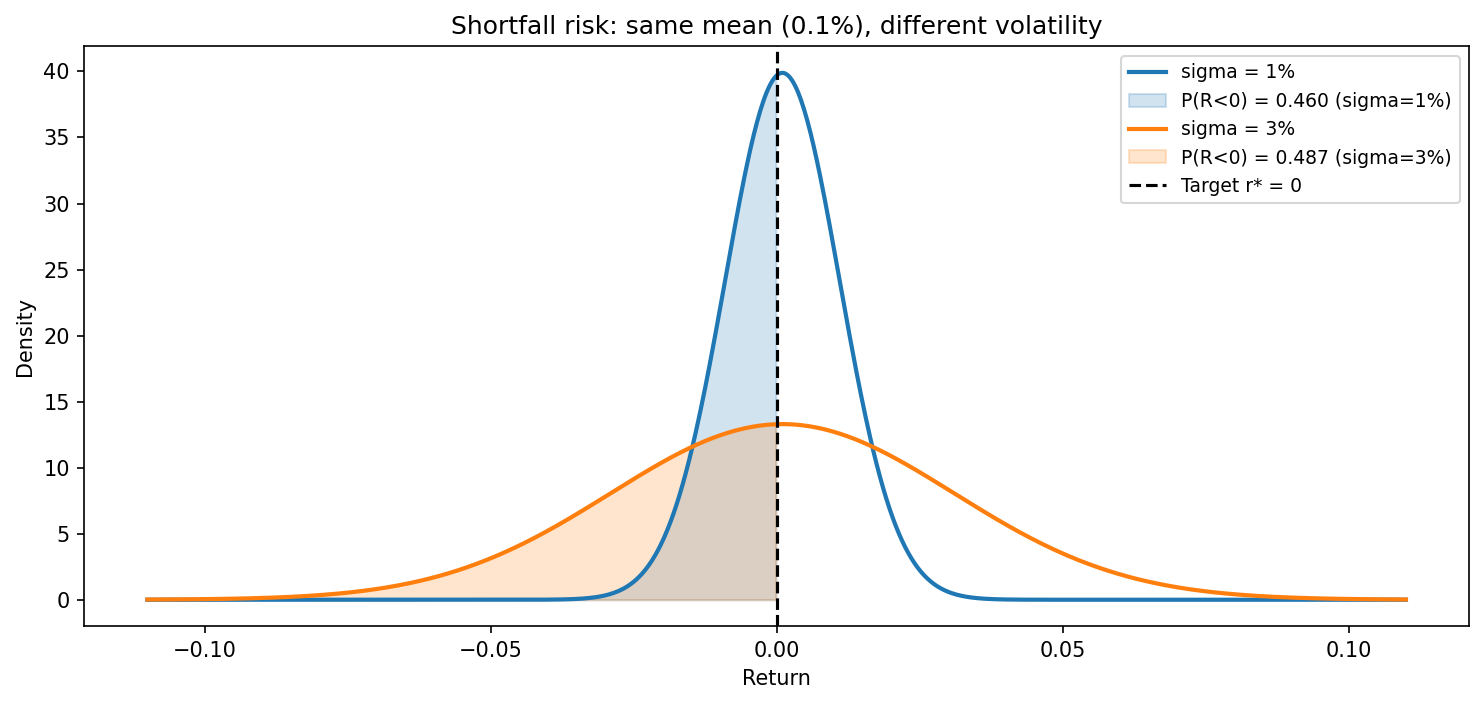

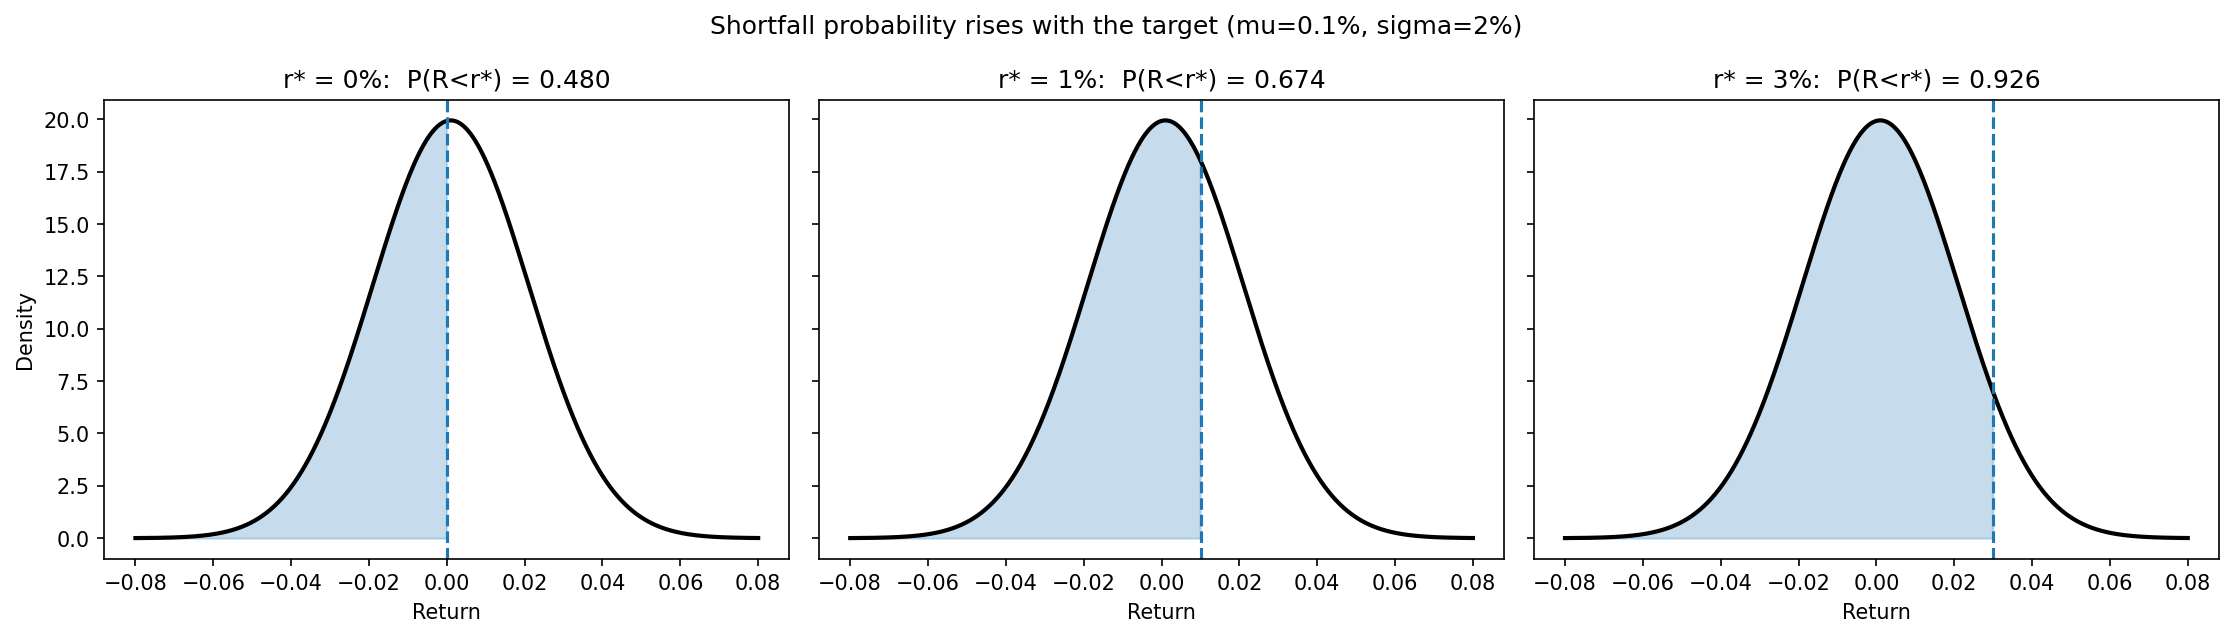

In [5]:
risk_theory = risk_exposition(); display(risk_theory)
display(Image(filename=str(FIGURE_DIR / "06_shortfall_risk_comparison.png")))
display(Image(filename=str(FIGURE_DIR / "07_shortfall_risk_targets.png")))

**Graph interpretation.** 같은 mean에서도 volatility가 높으면 target 왼쪽 density mass가 달라집니다. 또한 같은 distribution이라도 target을 높이면 shortfall probability가 증가합니다. 즉 Shortfall Risk는 경제적으로 정한 target에 의존합니다.

## Value at Risk (VaR) and sign convention

return variable의 lower-tail quantile을
$$\boxed{q_\alpha=F_R^{-1}(\alpha)},\qquad P(R\le q_\alpha)=\alpha$$
로 정의합니다. $q_{0.05}=-0.032$이면 return이 -3.2% 이하일 확률이 5%입니다.

loss $L=-R$를 쓰는 전통적 risk management에서는 $VaR_{0.95}(L)=F_L^{-1}(0.95)$를 양의 손실액으로 보고할 수 있습니다. 따라서 5% return quantile -3.2%는 약 95% loss VaR +3.2%와 대응합니다. 이 노트북의 표와 그림은 **return-quantile convention**을 사용합니다.

## Expected Shortfall (ES)

**Expected Shortfall (ES)**은 문헌 일부에서 **Conditional Value at Risk (CVaR)**라고도 합니다.
$$\boxed{ES_\alpha=E[R\mid R\le q_\alpha]}.$$

Value at Risk는 “worst $\alpha$% tail이 어디서 시작하는가?”, Expected Shortfall은 “그 tail 내부 평균 결과가 얼마나 나쁜가?”에 답합니다.

| Measure | Reference | Main question |
|---|---|---|
| Shortfall Risk | target $r^*$ | Will I miss my required return? |
| Value at Risk (VaR) | quantile $\alpha$ | Where does the extreme tail begin? |
| Expected Shortfall (ES) | tail below VaR | How bad is the average extreme-tail outcome? |

Shortfall Risk는 economically chosen target을, VaR와 ES는 distributional tail probability를 기준으로 합니다.

## Gaussian analytical example and Monte Carlo estimators

$R=\mu+\sigma Z$, $Z\sim N(0,1)$에서 $z_{.05}=\Phi^{-1}(.05)\approx-1.645$. 따라서 $\mu=.0005,\sigma=.02$이면
$$q_{.05}=\mu+\sigma z_{.05}\approx-.0324=-3.24\%.$$

$\Phi$는 standard normal CDF, $\phi$는 PDF이며
$$\boxed{ES_\alpha=\mu-\sigma\frac{\phi(z_\alpha)}{\alpha}}.$$
$\phi(z_{.05})\approx.103$이므로 $ES_{.05}\approx\mu-2.06\sigma\approx-4.07\%$.

Generated samples $R^{(1)},\ldots,R^{(M)}$에 대해
$$\widehat P(R<r^*)=M^{-1}\sum_m\mathbf1\{R^{(m)}<r^*\},$$
$\widehat q_\alpha$는 empirical alpha-quantile이고,
$$\widehat{ES}_\alpha=\frac{\sum_mR^{(m)}\mathbf1\{R^{(m)}\le\widehat q_\alpha\}}{\sum_m\mathbf1\{R^{(m)}\le\widehat q_\alpha\}}.$$
$m$은 scenario index, indicator는 조건 충족 시 1, 분모는 tail sample 수, 분자는 tail returns의 합입니다.

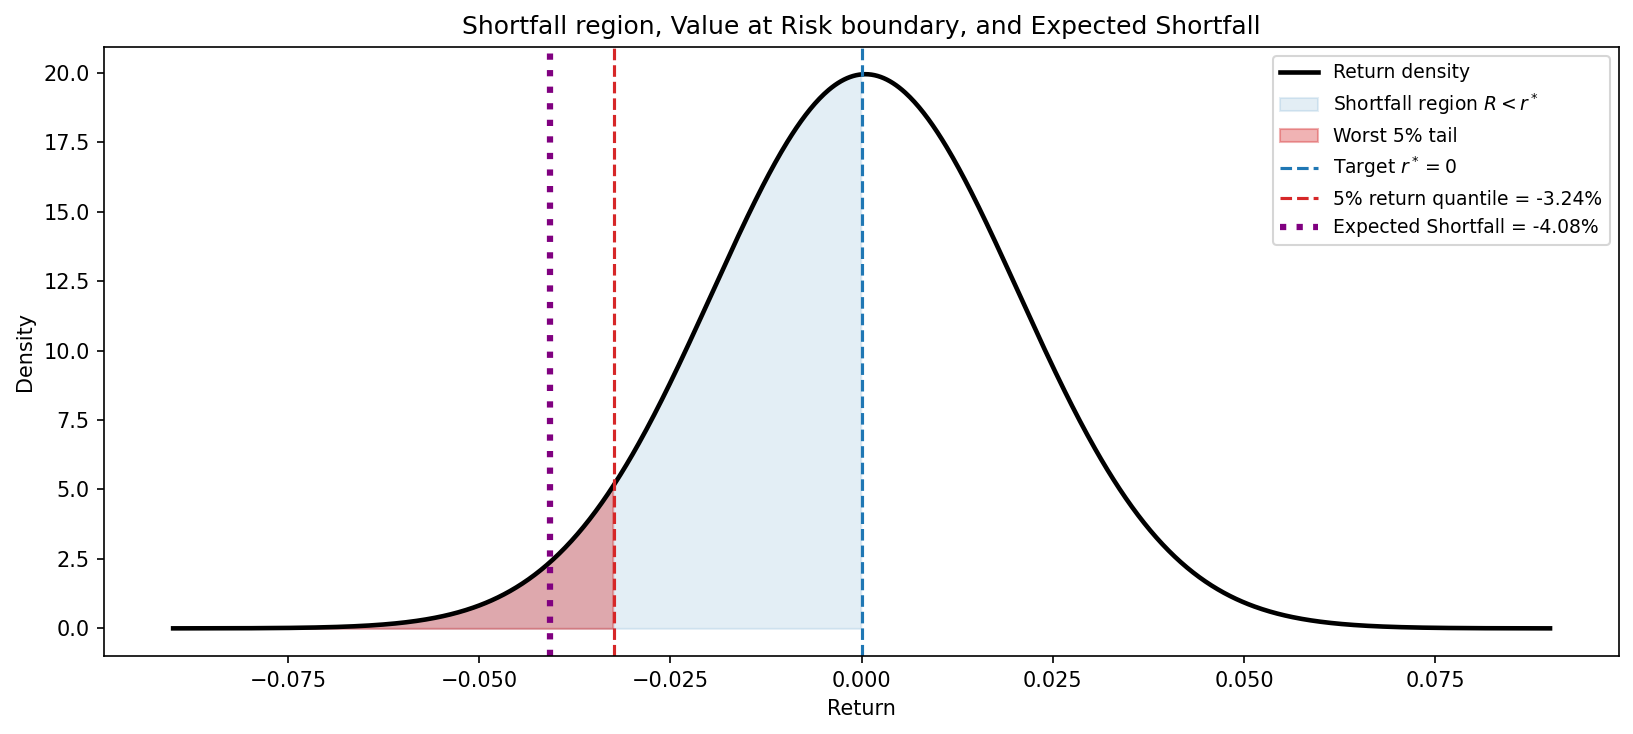

In [6]:
display(Image(filename=str(FIGURE_DIR / "08_shortfall_var_es_comparison.png")))

**Integrated graph interpretation.** 파란 영역은 target 미달 전체, 빨간 진한 영역은 그중 worst 5% tail, red dashed line은 VaR boundary, purple marker는 tail-average인 Expected Shortfall입니다. 서로 기준과 질문이 다릅니다.

<!-- LAB_END -->

<!-- ASSIGNMENT_1_START -->
# ASSIGNMENT_1 — Monte Carlo Precision

$\operatorname{SE}(\bar\epsilon)=1/\sqrt N$. 여러 $N$에서 실험을 반복하여 sample mean의 empirical RMSE와 empirical standard error를 theoretical $N^{-1/2}$와 비교하십시오. 완성 code, RMSE, empirical/theoretical SE table, figure와 3–5문장 해석을 제출하십시오. Monte Carlo error를 절반으로 줄이려면 simulation이 약 몇 배 필요한지도 답하십시오.

,N,Empirical RMSE,Empirical SE,Theoretical SE = 1/sqrt(N),Ratio (Emp SE / Theory)
0,10,0.319010,0.319086,0.316228,1.009040
1,100,0.098584,0.098603,0.100000,0.986030
2,1000,0.031737,0.031744,0.031623,1.003833
3,10000,0.010034,0.010029,0.010000,1.002916
4,100000,0.003127,0.003127,0.003162,0.988936


reps = 2,000,  log-log slope of RMSE vs N = -0.501  (theory: -0.5)
Error를 1/2로 줄이려면 N'/N = 4.0 배 (약 4배) 필요
N 10배 증가 시 RMSE 비율 (N=1,000 -> 10,000): 0.316 (theory 1/sqrt(10) = 0.316)


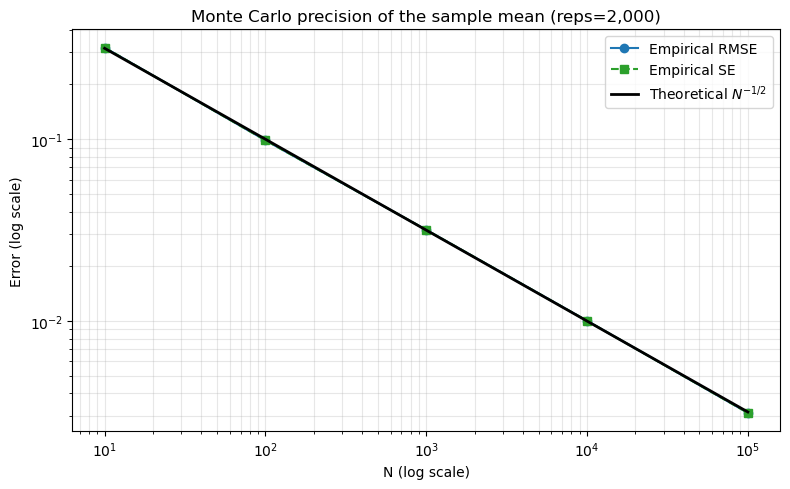

In [7]:
# ASSIGNMENT_1 — Monte Carlo precision: empirical RMSE / SE vs theoretical 1/sqrt(N)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Ns = [10, 100, 1_000, 10_000, 100_000]
reps = 2_000                                   # 각 N에서 반복 실험 횟수
rng = np.random.default_rng([SEED, 1001])      # 독립 난수 stream (재현 가능)

rows = []
for N in Ns:
    # reps번 반복: 매번 eps_1..eps_N ~ N(0,1)를 새로 뽑아 sample mean 계산
    means = np.array([rng.standard_normal(N).mean() for _ in range(reps)])
    rmse = np.sqrt(np.mean(means ** 2))        # true mean = 0 이므로 RMSE = sqrt(E[(mean-0)^2])
    emp_se = means.std(ddof=1)                 # sample mean의 empirical standard error
    rows.append({"N": N, "Empirical RMSE": rmse, "Empirical SE": emp_se,
                 "Theoretical SE = 1/sqrt(N)": N ** -0.5,
                 "Ratio (Emp SE / Theory)": emp_se / N ** -0.5})

assignment_1_result = pd.DataFrame(rows)
display(assignment_1_result.round(6))

# log-log slope: 이론상 -0.5
slope = np.polyfit(np.log(assignment_1_result["N"]), np.log(assignment_1_result["Empirical RMSE"]), 1)[0]
print(f"reps = {reps:,},  log-log slope of RMSE vs N = {slope:.3f}  (theory: -0.5)")

# error를 절반으로: 1/sqrt(N') = 0.5 / sqrt(N)  ->  N' = 4N
print("Error를 1/2로 줄이려면 N'/N =", (1 / 0.5) ** 2, "배 (약 4배) 필요")
print(f"N 10배 증가 시 RMSE 비율 (N=1,000 -> 10,000): "
      f"{assignment_1_result['Empirical RMSE'][3] / assignment_1_result['Empirical RMSE'][2]:.3f} "
      f"(theory 1/sqrt(10) = {10 ** -0.5:.3f})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(assignment_1_result["N"], assignment_1_result["Empirical RMSE"], "o-",
          color="tab:blue", label="Empirical RMSE")
ax.loglog(assignment_1_result["N"], assignment_1_result["Empirical SE"], "s--",
          color="tab:green", label="Empirical SE")
ax.loglog(assignment_1_result["N"], assignment_1_result["Theoretical SE = 1/sqrt(N)"], "k-",
          lw=2, label=r"Theoretical $N^{-1/2}$")
ax.set(title=f"Monte Carlo precision of the sample mean (reps={reps:,})",
       xlabel="N (log scale)", ylabel="Error (log scale)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "assignment_1_mc_precision.png", dpi=150, bbox_inches="tight")
plt.show()


### Your interpretation

각 $N$에서 sample mean $\bar\epsilon_N$을 2,000번 반복 생성하여 구한 empirical RMSE와 empirical SE는 theoretical $N^{-1/2}$와 거의 일치하며, 표의 Ratio가 1 근처이고 log-log 그래프에서 기울기가 약 $-0.5$인 직선으로 나타납니다. $\epsilon_i$가 iid $N(0,1)$이고 true mean이 0이므로 $\bar\epsilon_N$은 unbiased이고, 따라서 RMSE는 standard error와 같아져 $\sqrt{\operatorname{Var}(\bar\epsilon_N)}=1/\sqrt N$가 됩니다. 남는 작은 차이는 반복 횟수가 유한(reps=2,000)해서 생기는 sampling variability이며, $N$을 키워도 이 반복 간 변동 때문에 오차가 매 단계 단조롭게 줄어들지는 않을 수 있습니다. 오차가 $N^{-1/2}$로 줄어들기 때문에 Monte Carlo error를 절반으로 줄이려면 simulation 횟수를 약 **4배**로 늘려야 하고, 10배 정밀해지려면 100배가 필요합니다. 이처럼 수렴이 느리다는 점이 Monte Carlo의 계산 비용이며, 이후 risk measure 계산에서 $M$을 크게 잡는 이유입니다.

<!-- ASSIGNMENT_1_END -->

<!-- ASSIGNMENT_2_START -->
# ASSIGNMENT_2 — Verify $q(x_s\mid x_0)$

$x_0=.02$, $\bar\alpha_s=.40$을 고정하고
$$x_s=\sqrt{\bar\alpha_s}x_0+\sqrt{1-\bar\alpha_s}\epsilon$$
을 반복 생성하십시오. 이론적 conditional mean $\sqrt{\bar\alpha_s}x_0$와 variance $1-\bar\alpha_s$를 empirical 값과 비교하십시오. 완성 code, comparison table, histogram, theoretical mean marker와 3–5문장 해석이 필요합니다. 또한 intermediate states 없이 direct sampling이 가능한 이유를 설명하십시오.

,Quantity,Theoretical,Empirical,AbsDiff
0,Mean sqrt(abar)*x0,0.012649,0.012596,0.000053
1,Variance 1-abar,0.600000,0.599456,0.000544
2,Std sqrt(1-abar),0.774597,0.774245,0.000351
3,P(x_s <= theoretical mean),0.500000,0.499688,0.000312


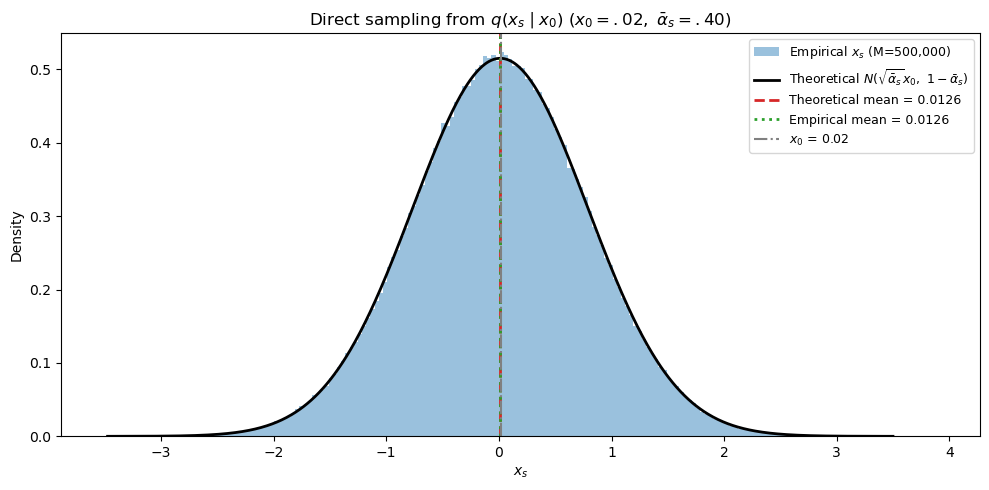

In [8]:
# ASSIGNMENT_2 — Verify q(x_s | x_0) = N( sqrt(abar) x_0 , 1 - abar )
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x0, abar = 0.02, 0.40
M = 500_000
rng = np.random.default_rng([SEED, 2002])      # 독립 난수 stream (재현 가능)

eps = rng.standard_normal(M)
xs = np.sqrt(abar) * x0 + np.sqrt(1 - abar) * eps      # direct sampling (중간 단계 없음)

th_mean, th_var = np.sqrt(abar) * x0, 1 - abar
th_std = np.sqrt(th_var)

assignment_2_result = pd.DataFrame({
    "Quantity": ["Mean  sqrt(abar)*x0", "Variance  1-abar", "Std  sqrt(1-abar)",
                 "P(x_s <= theoretical mean)"],
    "Theoretical": [th_mean, th_var, th_std, 0.5],
    "Empirical": [xs.mean(), xs.var(ddof=1), xs.std(ddof=1), np.mean(xs <= th_mean)],
})
assignment_2_result["AbsDiff"] = (assignment_2_result["Empirical"] - assignment_2_result["Theoretical"]).abs()
display(assignment_2_result.round(6))

grid = np.linspace(th_mean - 4.5 * th_std, th_mean + 4.5 * th_std, 800)
pdf = np.exp(-0.5 * ((grid - th_mean) / th_std) ** 2) / (th_std * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(xs, bins=200, density=True, color="tab:blue", alpha=0.45,
        label=f"Empirical $x_s$ (M={M:,})")
ax.plot(grid, pdf, color="black", lw=2, label=r"Theoretical $N(\sqrt{\bar\alpha_s}x_0,\ 1-\bar\alpha_s)$")
ax.axvline(th_mean, color="tab:red", ls="--", lw=2, label=f"Theoretical mean = {th_mean:.4f}")
ax.axvline(xs.mean(), color="tab:green", ls=":", lw=2, label=f"Empirical mean = {xs.mean():.4f}")
ax.axvline(x0, color="gray", ls="-.", label=f"$x_0$ = {x0}")
ax.set(title=r"Direct sampling from $q(x_s\mid x_0)$ ($x_0=.02,\ \bar\alpha_s=.40$)",
       xlabel=r"$x_s$", ylabel="Density")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "assignment_2_forward_marginal.png", dpi=150, bbox_inches="tight")
plt.show()


### Your interpretation

$x_0=.02$, $\bar\alpha_s=.40$에서 이론적 conditional mean은 $\sqrt{.40}\times.02\approx.01265$, variance는 $1-.40=.60$이며, 500,000개 샘플로 계산한 empirical mean과 variance는 표에서 이 값과 Monte Carlo 오차 범위 안에서 일치합니다. 이는 $x_s$가 $\epsilon\sim N(0,1)$의 affine 변환이므로 $E[x_s]=\sqrt{\bar\alpha_s}x_0$, $\operatorname{Var}(x_s)=(1-\bar\alpha_s)\operatorname{Var}(\epsilon)=1-\bar\alpha_s$이고, Gaussian의 affine 변환은 다시 Gaussian이기 때문입니다. 히스토그램이 이론 density $N(\sqrt{\bar\alpha_s}x_0,\,1-\bar\alpha_s)$를 따르고 평균 marker가 분포 중심에 놓이는 것도 같은 결과입니다. 평균이 $x_0=.02$보다 작은 값으로 줄고 분산이 크다는 점에서, 이 단계의 $x_s$는 원래 신호가 약해지고 noise가 지배적인 상태입니다.

**Intermediate states 없이 direct sampling이 가능한 이유.** forward process의 각 step은 Gaussian transition이고, Gaussian의 합성(독립 Gaussian noise의 합은 Gaussian이며 분산이 더해짐)은 닫힌 형태로 정리됩니다. 그래서 $s$번의 step을 모두 합치면 $\bar\alpha_s=\prod_{k\le s}\alpha_k$만으로 $q(x_s\mid x_0)=N(\sqrt{\bar\alpha_s}x_0,(1-\bar\alpha_s)I)$가 되어, $x_1,\dots,x_{s-1}$을 만들지 않고 $\epsilon$ 한 번으로 $x_s$를 바로 뽑을 수 있습니다. 계산 비용이 $s$ step 순차 시뮬레이션에서 $O(1)$로 줄기 때문에, 학습 때 임의의 time step $s$를 무작위로 골라 $(x_s,\epsilon)$ 쌍을 빠르게 만들 수 있다는 점이 diffusion model 학습의 핵심 이점입니다.

<!-- ASSIGNMENT_2_END -->

<!-- ASSIGNMENT_3_START -->
# ASSIGNMENT_3 — Generated Scenarios and Financial Risk Measures

$R=\mu+\sigma\epsilon$에서 $\mu=.0005$, $\sigma=.02$, $r^*=0$, $\alpha=.05$, $M\ge200{,}000$을 사용하십시오.

반드시 계산할 항목은 (1) sample mean, (2) sample standard deviation, (3) Shortfall Probability $P(R<r^*)$, (4) Mean Target Shortfall $E[(r^*-R)^+]$, (5) 5% lower-tail Value at Risk / return quantile $q_{.05}$, (6) 5% Expected Shortfall $ES_{.05}$, (7) downside deviation입니다.

summary DataFrame과 histogram/density figure를 만드십시오. 그림에는 target $r^*$, VaR threshold, shaded shortfall region, shaded worst 5% tail, ES marker가 모두 있어야 합니다. 마지막으로 아래 여섯 질문에 4–6문장 이상으로 답하십시오.

1. Shortfall Risk는 무엇을 측정하는가?
2. Value at Risk는 무엇을 측정하는가?
3. Expected Shortfall은 무엇을 측정하는가?
4. Shortfall Risk와 VaR는 어떻게 다른가?
5. VaR와 Expected Shortfall은 어떻게 다른가?
6. generated scenarios가 왜 이 risk measures를 계산 가능하게 하는가?

,Measure,Analytical,Empirical,AbsDiff
0,Sample mean,0.000500,0.000495,0.000005
1,Sample std,0.020000,0.019990,0.000010
2,Shortfall Probability P(R<r*),0.490027,0.489564,0.000463
3,Mean Target Shortfall E[(r*-R)+],0.007731,0.007731,0.000000
4,5% VaR / quantile q_.05,-0.032397,-0.032416,0.000019
5,5% Expected Shortfall ES_.05,-0.040754,-0.040778,0.000024
6,Downside deviation,0.013862,0.013866,0.000005


M = 500,000,  VaR loss convention = -q = 3.2416%,  ES loss = -ES = 4.0778%


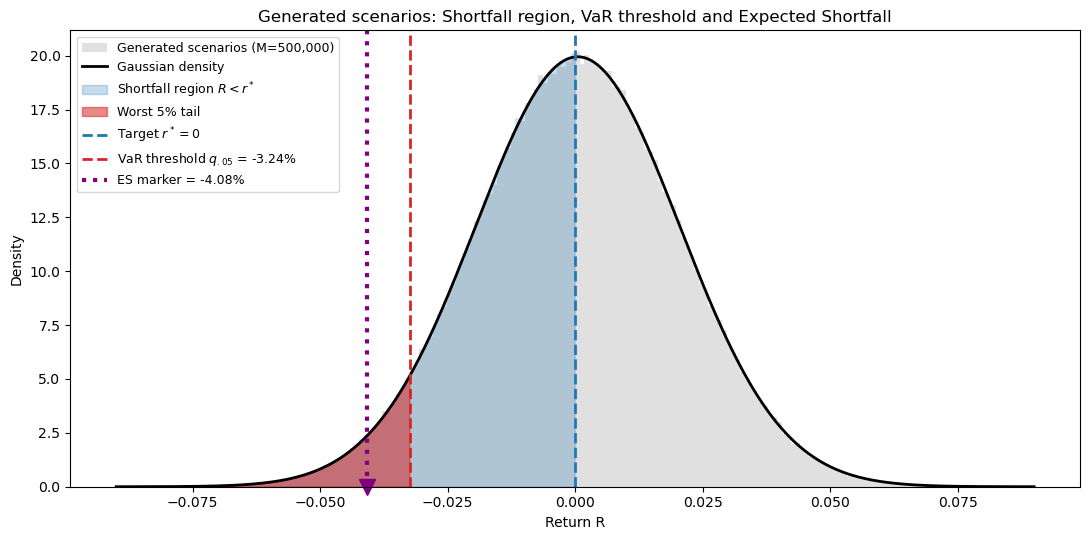

In [9]:
# ASSIGNMENT_3 — Generated scenarios -> financial risk measures
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist

mu, sigma, r_star, alpha = 0.0005, 0.02, 0.0, 0.05
M = 500_000                                   # M >= 200,000

# 1) generated scenarios: R = mu + sigma * eps,  eps ~ N(0,1)
rng = np.random.default_rng([SEED, 3003])     # 독립 난수 stream (재현 가능)
eps = rng.standard_normal(M)
R = mu + sigma * eps

# 2) Monte Carlo estimators
sample_mean = R.mean()
sample_std = R.std(ddof=1)
shortfall_prob = np.mean(R < r_star)                      # P(R < r*)
mts = np.mean(np.maximum(r_star - R, 0.0))                # E[(r* - R)^+]
q_alpha = np.quantile(R, alpha)                           # 5% VaR / return quantile
tail = R[R <= q_alpha]
es_alpha = tail.mean()                                    # E[R | R <= q_alpha]
downside_dev = np.sqrt(np.mean(np.maximum(r_star - R, 0.0) ** 2))   # sqrt(LPM2)

# 3) Gaussian analytical values
N01 = NormalDist()
d = (r_star - mu) / sigma
z = N01.inv_cdf(alpha)
th_sp = N01.cdf(d)
th_mts = sigma * (d * N01.cdf(d) + N01.pdf(d))
th_q = mu + sigma * z
th_es = mu - sigma * N01.pdf(z) / alpha
th_dd = np.sqrt(sigma ** 2 * ((d ** 2 + 1) * N01.cdf(d) + d * N01.pdf(d)))

assignment_3_result = pd.DataFrame({
    "Measure": ["Sample mean", "Sample std", "Shortfall Probability P(R<r*)",
                "Mean Target Shortfall E[(r*-R)+]", "5% VaR / quantile q_.05",
                "5% Expected Shortfall ES_.05", "Downside deviation"],
    "Analytical": [mu, sigma, th_sp, th_mts, th_q, th_es, th_dd],
    "Empirical": [sample_mean, sample_std, shortfall_prob, mts, q_alpha, es_alpha, downside_dev],
})
assignment_3_result["AbsDiff"] = (assignment_3_result["Empirical"] - assignment_3_result["Analytical"]).abs()
display(assignment_3_result.round(6))
print(f"M = {M:,},  VaR loss convention = -q = {-q_alpha:.4%},  ES loss = -ES = {-es_alpha:.4%}")

# 4) figure: histogram/density + target, VaR, shortfall region, worst 5% tail, ES
grid = np.linspace(-0.09, 0.09, 1000)
pdf = np.exp(-0.5 * ((grid - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(R, bins=200, range=(-0.09, 0.09), density=True, color="lightgray", alpha=0.7,
        label=f"Generated scenarios (M={M:,})")
ax.plot(grid, pdf, color="black", lw=2, label="Gaussian density")
ax.fill_between(grid, pdf, where=grid < r_star, color="tab:blue", alpha=0.25,
                label=r"Shortfall region $R<r^*$")
ax.fill_between(grid, pdf, where=grid <= q_alpha, color="tab:red", alpha=0.55,
                label="Worst 5% tail")
ax.axvline(r_star, color="tab:blue", ls="--", lw=2, label=r"Target $r^*=0$")
ax.axvline(q_alpha, color="tab:red", ls="--", lw=2, label=f"VaR threshold $q_{{.05}}$ = {q_alpha:.2%}")
ax.axvline(es_alpha, color="purple", ls=":", lw=3, label=f"ES marker = {es_alpha:.2%}")
ax.plot([es_alpha], [0], marker="v", color="purple", ms=12, clip_on=False)
ax.set(title="Generated scenarios: Shortfall region, VaR threshold and Expected Shortfall",
       xlabel="Return R", ylabel="Density")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "assignment_3_risk_measures.png", dpi=150, bbox_inches="tight")
plt.show()


### Your interpretation

**실험 결과 비교.** M=500,000개의 generated scenarios $R=\mu+\sigma\epsilon$로 계산한 empirical 값은 위 표의 Gaussian analytical 값과 매우 가깝고, 차이는 Monte Carlo sampling variability 수준입니다. 특히 sample mean은 $\mu=0.05\%$, sample std는 $\sigma=2\%$ 근처이며, 5% quantile은 약 $-3.2\%$, ES는 약 $-4.1\%$로 ES가 VaR보다 더 왼쪽(더 나쁜 손실)에 위치합니다. 아래 답변에서 VaR는 return quantile $q_{.05}$로 두며, 손실 크기로 보고할 때는 $-q_{.05}$를 사용합니다.

**1. Shortfall Risk는 무엇을 측정하는가?**
Shortfall Risk는 수익률 $R$이 투자자가 정한 target return $r^*$에 미달할 위험을 측정합니다. 대표적으로 Shortfall Probability $P(R<r^*)$는 target을 못 맞출 확률이고, Mean Target Shortfall $E[(r^*-R)^+]$는 미달할 때 그 폭까지 평균적으로 반영한 값입니다. 즉 "목표를 얼마나 자주, 또 얼마나 크게 놓치는가"를 보는 목표 기준(target-based) 위험 지표입니다. $r^*$ 아래쪽만 계산하므로 upside 변동성은 위험으로 취급하지 않는 downside risk 관점이며, downside deviation 같은 Lower Partial Moment 지표와 같은 계열입니다. 이 과제에서는 $r^*=0$이므로 "손실이 날 확률과 그 평균 크기"로 해석할 수 있습니다.

**2. Value at Risk는 무엇을 측정하는가?**
VaR는 신뢰수준 $1-\alpha$에서 분포의 하위 $\alpha$ 꼬리가 시작되는 경계, 즉 lower-tail quantile $q_\alpha=F_R^{-1}(\alpha)$를 측정합니다. $\alpha=5\%$이면 "수익률이 $q_{.05}$보다 나쁠 확률이 5%"이며, 나머지 95%의 경우에는 그보다 좋은 결과가 나온다는 뜻입니다. 이 값을 손실 크기로 말할 때는 부호를 바꿔 $\text{VaR}=-q_{.05}$로 보고합니다. VaR는 꼬리가 시작되는 지점의 문턱값일 뿐, 그 문턱을 넘은 뒤 얼마나 더 나빠질 수 있는지는 알려주지 않습니다. 또한 target $r^*$와 무관하게 확률 수준 $\alpha$로 정의됩니다.

**3. Expected Shortfall은 무엇을 측정하는가?**
Expected Shortfall은 최악의 $\alpha$ 꼬리 안에서의 평균 수익률 $ES_\alpha=E[R\mid R\le q_\alpha]$, 즉 "VaR 경계를 넘는 나쁜 상황이 실제로 발생했을 때의 평균적인 결과"를 측정합니다(문헌에 따라 CVaR이라고도 부릅니다). 따라서 tail의 확률뿐 아니라 tail 안의 깊이와 모양을 반영합니다. 이 실험에서는 ES가 VaR보다 더 낮은 수익률(더 큰 손실)로 나타났고, 이는 꼬리 평균이 항상 경계값보다 더 나쁘기 때문입니다. 손실 크기로는 $-ES_\alpha$로 보고하며 tail risk를 요약하는 데 VaR보다 정보가 많습니다.

**4. Shortfall Risk와 VaR는 어떻게 다른가?**
Shortfall Risk는 target $r^*$를 입력으로 주고 "그 아래로 갈 확률/크기"를 출력하는 반면, VaR는 확률 $\alpha$를 입력으로 주고 "그 확률에 해당하는 수익률 경계"를 출력합니다. 즉 두 지표는 서로 역(inverse) 방향의 질문이며, 같은 분포의 CDF $F_R$를 한쪽은 $F_R(r^*)$로, 다른 쪽은 $F_R^{-1}(\alpha)$로 읽는 것입니다. 이 실험에서 $r^*=0$의 shortfall probability는 약 49.0%인 반면 5% VaR 경계는 약 $-3.2\%$로, 파란 shortfall 영역이 빨간 worst-5% 꼬리보다 훨씬 넓습니다. Shortfall Risk는 목표 달성 여부를, VaR는 극단적 손실 수준을 다루므로 사용 목적이 다릅니다.

**5. VaR와 Expected Shortfall은 어떻게 다른가?**
둘 다 같은 하위 $\alpha$ 꼬리를 보지만, VaR는 그 꼬리의 입구(경계 quantile)이고 ES는 꼬리 안쪽 전체의 평균입니다. 그래서 $ES_\alpha\le q_\alpha$(수익률 기준)이며 손실로는 ES가 VaR 이상입니다. 두 분포가 같은 VaR를 가져도 꼬리가 두꺼워 극단 손실이 더 큰 분포는 ES가 더 크게 나타나 차이를 구분할 수 있습니다. 또한 ES는 subadditivity를 만족하는 coherent risk measure이지만 VaR는 일반적으로 그렇지 않습니다. 대신 VaR는 해석과 추정이 단순하고, ES는 꼬리 표본 수가 적으면 추정 변동성이 커진다는 점이 trade-off입니다.

**6. generated scenarios가 왜 이 risk measures를 계산 가능하게 하는가?**
이 모든 지표는 수익률 분포 $p_R$에 대한 기댓값 또는 quantile이며, scenario가 충분히 많으면 sample average와 empirical quantile로 근사할 수 있습니다. 예를 들어 $P(R<r^*)$는 $\frac1M\sum \mathbf 1\{R^{(i)}<r^*\}$, MTS는 $\frac1M\sum (r^*-R^{(i)})^+$, VaR는 정렬된 표본의 5% 지점, ES는 그 지점 이하 표본들의 평균으로 계산됩니다. 즉 닫힌 형태의 적분이나 해석해가 없어도 scenario만 생성하면 같은 코드로 모든 지표를 얻을 수 있습니다. 이는 law of large numbers 덕분에 $M$이 커질수록 오차가 $M^{-1/2}$로 줄어드는 것과 연결됩니다. 이 관점은 Gaussian 대신 heavy tail이나 volatility clustering을 가진 diffusion model의 generated scenarios에도 그대로 적용되므로, 생성모형의 품질이 곧 risk measure의 품질을 결정합니다.

<!-- ASSIGNMENT_3_END -->

<!-- CONCEPT_CHECK_START -->
# CONCEPT_CHECK

1. Distribution과 sample의 차이는 무엇인가?
2. Monte Carlo simulation과 diffusion model의 핵심 차이는 무엇인가?
3. Monte Carlo sample average가 expectation을 근사하는 이유는 무엇인가?
4. Reparameterization은 무엇을 분리하는가?
5. Gaussian noise가 diffusion에 편리한 이유는 무엇인가?
6. Forward diffusion은 forecasting인가? 이유를 설명하라.
7. Financial time $t$와 diffusion step $s$의 차이는 무엇인가?
8. Shortfall Risk를 정의하라.
9. VaR의 전체 영문 명칭과 return-quantile 의미를 설명하라.
10. ES의 전체 영문 명칭과 의미를 설명하라.
11. Shortfall Risk와 VaR의 기준은 어떻게 다른가?
12. VaR와 Expected Shortfall은 어떻게 다른가?
13. Diffusion-generated scenarios와 Monte Carlo risk measurement는 어떻게 연결되는가?

## Your responses

<!-- CONCEPT_CHECK_END -->

**1.** 분포는 확률변수가 어떤 값을 어떤 확률로 가질지를 정하는 확률법칙을 의미합니다. 그리고 샘플은 그중에 뽑힌 실현값(realization) 한 개를 의미합니다. 즉, 경로 한 개를 의미합니다.

**2.** 가장 핵심적인 것은 몬테카를로 같은 경우는 이미 주어진 분포에서 샘플을 뽑아 기댓값이나 확률 같은 값을 계산하는 방법이고, diffusion model은 그 분포 자체를 데이터에서 학습하는 모델이라고 보면 될 것 같습니다.

**3.** 대수의 법칙 때문입니다. 만약에 시행을 무한대로 하며 평균을 낼 경우 샘플 평균은 원래 분포의 기댓값으로 수렴하는 법칙입니다. 따라서 몬테카를로로 시행을 여러 번 한다면 기댓값을 근사할 수 있다고 봅니다.

**4.** Reparameterization은 randomness(표준 노이즈 $\epsilon$)와 분포 파라미터($\mu$, $\sigma$)를 분리합니다. 딥러닝 학습 과정(순전파 → 오차 계산 → 역전파 → 경사하강법) 중, 순전파에서 확률적 샘플링이 필요할 때 확률적 노이즈($\epsilon$)를 연산 밖으로 빼내어 모델 파라미터($\mu$, $\sigma$)와 분리해 주는 기법입니다.

일반적인 딥러닝 연산은 입력과 출력이 1:1로 고정된 결정론적 연산이라 역전파 미분이 매끄럽게 이루어집니다. 역전파의 기울기 계산은 "입력을 미세하게 바꿨을 때 출력이 얼마나 일정하게 변하는가?"를 추적하는 규칙적인 도구이기 때문입니다.

하지만 생성 모델처럼 순전파 중간에 확률적 샘플링이 직접 들어가 버리면, 오차가 발생했을 때 이것이 파라미터를 바꾼 영향 때문인지 아니면 단순히 노이즈 때문인지 원인과 결과를 추적할 수 없어 수학적인 미분(기울기) 계산이 불가능해집니다.

Reparameterization Trick은 이러한 확률성을 외부 표준 노이즈 $\epsilon\sim N(0,I)$로 격리하고, 신경망 자체는 파라미터를 통한 결정론적 연산 $X=\mu+\sigma\epsilon$만 수행하도록 바꿉니다. 이를 통해 끊겼던 미분 경로를 이어주어, 역전파 시 파라미터에 대한 기울기(Gradient)를 정상적으로 계산하고 모델을 학습시킬 수 있게 만들어 줍니다.

**5.** 데이터 자체가 정규분포여서가 아니라, 샘플링의 용이함, 선형 변환 및 합성에 대한 닫힘성으로 유도되는 Direct Sampling 공식, 역전파가 가능한 Reparameterization 구조, 브라운 운동 및 SDE와의 연계성 때문에 가우시안 노이즈가 diffusion 모델에 가장 편리한 선택이 됩니다.

**6.** Forward diffusion은 forecasting이 아닙니다. Forward 과정은 diffusion step $s$에 따라 데이터에 인위적으로 노이즈를 넣는, 사람이 정해둔 손상 규칙일 뿐이며 미래 시점 $t+1$의 수익률을 예측하지 않습니다. 딥러닝 최적화를 통해 학습하는 대상은 'Reverse(노이즈 제거) 과정'입니다. 이 Reverse 과정을 통해 학습된 조건부 분포에서 시나리오를 반복 생성(Sampling)해야 비로소 미래에 대한 확률적 예측이 됩니다.

**7.** 금융 시간 $t$는 시장 데이터가 실제로 관측되는 현실의 달력 시간이고, diffusion step $s$는 그 데이터를 모델 내부에서 인위적으로 노이즈화하거나 복원하는 알고리즘 연산 단계입니다.

**8.** Shortfall Risk는 수익률 $R$이 투자자가 미리 정한 목표수익률 $r^*$에 미달할 위험입니다. 대표적으로 Shortfall Probability $P(R<r^*)$로 목표를 못 맞출 확률을 측정하고, 미달 폭까지 보려면 Mean Target Shortfall $E[(r^*-R)^+]$를 사용합니다. $r^*=0$이면 손실이 날 확률이 됩니다.

**9.** Value at Risk. 수익률 분위수 $q_{0.05}(R)$는 "정상적인 시장 상황(95% 확률)에서 자산 수익률이 이 수준 아래로는 떨어지지 않는다"는 하방 방어선을 의미합니다. 만약 계산된 $q_{0.05}(R_{t+1})=-3\%$라면, "하루 동안 수익률이 -3%보다 더 크게 하락(폭락)할 확률은 5%에 불과하다"는 뜻이며, 이 -3% 자체가 수익률 기준의 하방 리스크(VaR 기준치)가 됩니다.

**10.** Expected Shortfall. 기준선(VaR)을 뚫고 지나가는 위기 상황이 터졌을 때 평균적으로 얼마나 큰 손실이 발생하는가, 즉 $ES_\alpha=E[R\mid R\le q_\alpha]$입니다.

**11.** Shortfall Risk는 투자자가 경제적으로 정한 목표수익률 $r^*$가 기준이며, 수익률이 그 기준선 아래로 미달(Shortfall)할 확률과 크기를 봅니다. 반면 VaR는 외부의 절대적 목표치가 아니라 확률수준 $\alpha$(예: 5%, 즉 신뢰수준 95%)가 기준이며, 수익률 분포 자체에서 그 확률에 해당하는 분위수(quantile) $q_\alpha$를 구한 값입니다.

**12.** 앞에서 언급했듯 VaR은 꼬리가 시작되는 임계값 그 자체입니다. 반면 Expected Shortfall은 손실 $L$이 기준선인 VaR를 뚫고 지나가는 최악의 상황(Tail Event)이 발생했을 때, 그 초과 손실 구간(꼬리 영역)에서 발생하는 조건부 평균 손실액입니다.

**13.** diffusion 모델로 조건부 분포에서 시나리오를 뽑아내고, 그걸로 몬테카를로 추정을 하면 VaR, ES, 신뢰구간과 같은 정량적 리스크 지표로 변환할 수 있습니다.


## Result Summary (자동 채점용)

In [10]:
# Assignment 2 결과 요약
print("[RESULT] A2_CONDITIONAL_MEAN =", xs.mean())
print("[RESULT] A2_CONDITIONAL_VARIANCE =", xs.var(ddof=1))

# Assignment 3 결과 요약
print("[RESULT] A3_SHORTFALL_PROBABILITY =", shortfall_prob)
print("[RESULT] A3_MEAN_TARGET_SHORTFALL =", mts)
print("[RESULT] A3_VAR_05 =", q_alpha)
print("[RESULT] A3_ES_05 =", es_alpha)

[RESULT] A2_CONDITIONAL_MEAN = 0.012595987148085325
[RESULT] A2_CONDITIONAL_VARIANCE = 0.5994556458189939
[RESULT] A3_SHORTFALL_PROBABILITY = 0.489564
[RESULT] A3_MEAN_TARGET_SHORTFALL = 0.007731065572312334
[RESULT] A3_VAR_05 = -0.03241638724478204
[RESULT] A3_ES_05 = -0.04077810495141684


# Grand Summary and Bridge to Week 03

Probability distribution → random variable → Gaussian noise → sampling → Monte Carlo → reparameterization → multivariate Gaussian → forward diffusion → generated scenarios → risk measures.

$$\boxed{x_s=\sqrt{\bar\alpha_s}x_0+\sqrt{1-\bar\alpha_s}\epsilon}$$

Forward diffusion은 별개의 trick이 아니라 structured, diffusion-step-dependent Gaussian reparameterization입니다. Week 03은 $q(x_s\mid x_{s-1})$를 formalize하고 $q(x_s\mid x_0)$를 유도합니다.

<!-- SUBMISSION_CHECKLIST_START -->
# 과제 제출 방법 — 반드시 확인

> **학생은 실행 완료된 `.ipynb` 파일 하나만 제출합니다.**

파일명 형식: `Diffusion_week02_학번_이름.ipynb`  
예시: `Diffusion_week02_20261234_홍길동.ipynb`

제출 notebook 하나에 Provided Lab과 Lab outputs, Assignment 1–3의 code/output/figure/interpretation, 모든 Concept Check 답변이 포함되어야 합니다.

## 제출 순서

1. Assignment 1, Assignment 2, Assignment 3을 모두 작성합니다.
2. Concept Check를 모두 작성합니다.
3. **Restart Kernel**을 실행합니다.
4. **Run All**을 실행합니다.
5. 모든 셀이 오류 없이 실행되는지 확인합니다.
6. 표와 figure가 notebook 안에 표시되는지 확인합니다.
7. **Save**합니다.
8. notebook을 닫았다 다시 열어 output과 figure가 보이는지 확인합니다.
9. 파일명이 지정 형식인지 확인합니다.
10. eClass에 `.ipynb` 파일 하나만 업로드합니다.

> **코드만 있고 output이 없는 notebook은 완전한 제출물이 아닙니다.**  
> **Assignment TODO가 남아 있으면 해당 부분은 미완성으로 간주될 수 있습니다.**  
> **빨간 traceback 또는 execution error가 남아 있으면 제출 전에 수정해야 합니다.**

## Do NOT submit

`.py`, `.csv`, `.png`, `.pdf`, `.zip`, `.venv/`, `__pycache__/`, `.ipynb_checkpoints/`

> 제출물은 실행 완료된 `.ipynb` 단일 파일입니다. ZIP, Python source, 별도 figure를 제출하지 마세요.

## 제출 전 Checklist

- [ ] 파일명을 `Diffusion_week02_학번_이름.ipynb` 형식으로 작성했다.
- [ ] 제공된 Lab 부분을 삭제하지 않았다.
- [ ] Lab outputs와 figures가 표시되어 있다.
- [ ] Assignment 1의 TODO, code, numerical output, RMSE/SE table, figure, 3–5문장 해석을 완료했다.
- [ ] Assignment 2의 TODO, theoretical/empirical table, histogram, mean marker, 3–5문장 해석을 완료했다.
- [ ] Assignment 3의 TODO와 summary DataFrame을 완료했다.
- [ ] Shortfall Probability와 Mean Target Shortfall을 계산했다.
- [ ] Value at Risk (VaR)와 Expected Shortfall (ES)을 계산했다.
- [ ] Assignment 3 figure에 target, shortfall region, VaR, 5% tail, ES marker가 있다.
- [ ] Assignment 3의 여섯 해석 질문에 4–6문장 이상 답했다.
- [ ] Concept Check의 13개 질문에 모두 답했다.
- [ ] Monte Carlo와 Diffusion의 차이를 설명했다.
- [ ] Restart Kernel → Run All을 수행했다.
- [ ] 모든 셀이 오류 없이 실행되었고 빨간 traceback이 없다.
- [ ] notebook을 저장하고 다시 열어 output과 figure를 확인했다.
- [ ] eClass에 `.ipynb` 파일 하나만 제출한다.

<!-- SUBMISSION_CHECKLIST_END -->